## Multiple linear regression

### Data description and analysis

<b> The Boston Housing Dataset: </b> the Boston Housing Dataset is derived from information collected by the U.S. Census Service regarding housing in the Boston, Massachusetts area. It aims to predict house prices based on various characteristics. 

<div class="alert alert-block alert-danger">
    
1. Import the Boston Housing dataset.
2. Display the correlation matrix and select only the highly correlated features with the label (MEDV feature) using a threshold value of 0.6.
3. Verify if the selected features represent a linear relationship with the target variable based on a 3D plot.
4. Split the generated dataset.
5. Normalize the data (excluding the label) using the min max scaler strategy.


<div/>

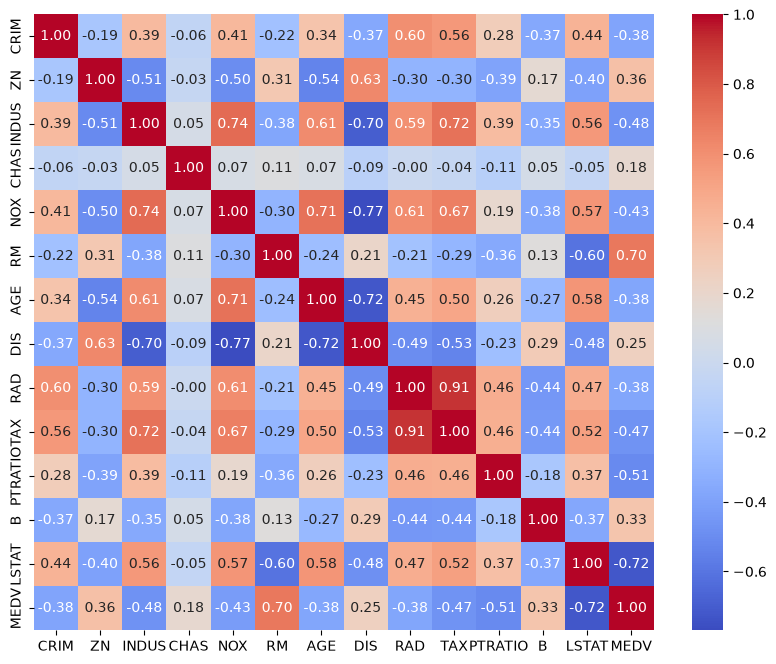

['RM', 'LSTAT']


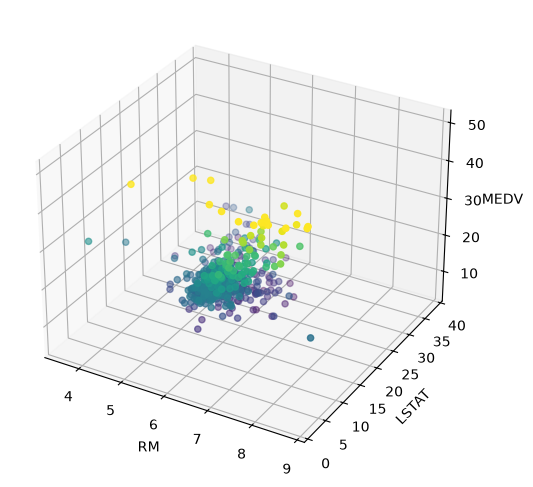

In [19]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Import (fill NAs with the median)
df = pd.read_csv("HousingData.csv")
df = df.fillna(df.median())

# 2. Correlation matrix + threshold 0.6
corr = df.corr()
plt.figure(figsize=(10,8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm"); 
plt.show()
feats = corr["MEDV"].drop("MEDV")
selected = feats[feats.abs() > 0.6].index.tolist()
print(selected)   # ['RM', 'LSTAT']

# 3. 3D plot: features vs target
fig = plt.figure(figsize=(8,6)); ax = fig.add_subplot(111, projection='3d')
ax.scatter(df[selected[0]], df[selected[1]], df["MEDV"], c=df["MEDV"], cmap="viridis")
ax.set_xlabel(selected[0]); ax.set_ylabel(selected[1]); ax.set_zlabel("MEDV"); plt.show()
# Observation: MEDV increases with RM and decreases with LSTAT -> roughly linear
# (slight curvature for LSTAT), so a linear model is reasonable.

# 4. Split
X, y = df[selected], df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Min-max scaling (fit on train only)
scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Data training and evaluation

<div class="alert alert-block alert-danger">
    
1. Use the following lines of code to perform training on the Boston Housing dataset.

<div/>

In [ ]:
from sklearn.linear_model import SGDRegressor
sgdr = SGDRegressor(learning_rate='invscaling', eta0=0.0001,max_iter=10000,verbose=1)

<div class="alert alert-block alert-danger">

2. Display the convergence graph of the trained model (where x represents the iterations and y is the loss).
3. Vary the learning rate value (0.01, 0.001, 0.0001). By comparing the convergence graphs for each model, what do you observe in terms of convergence and results?
4. Why does the graph not reach the maximum number of iterations when
using the 0.01 learning rate? Which variable controls this behavior?
5. Display the performance of the generated models on the test set based on the following metrics: MAE, MSE, RMSE, and R-squared. Select the best model based on these metrics.
6. Plot the generated plane of the best model and the scaled training data in one 3D plot. What do you observe?
7. Predict the class of the sample shown in the following figure based on the best model.    

<div/>

0.01 stopped after 228 iterations
0.001 stopped after 2091 iterations
0.0001 stopped after 7265 iterations


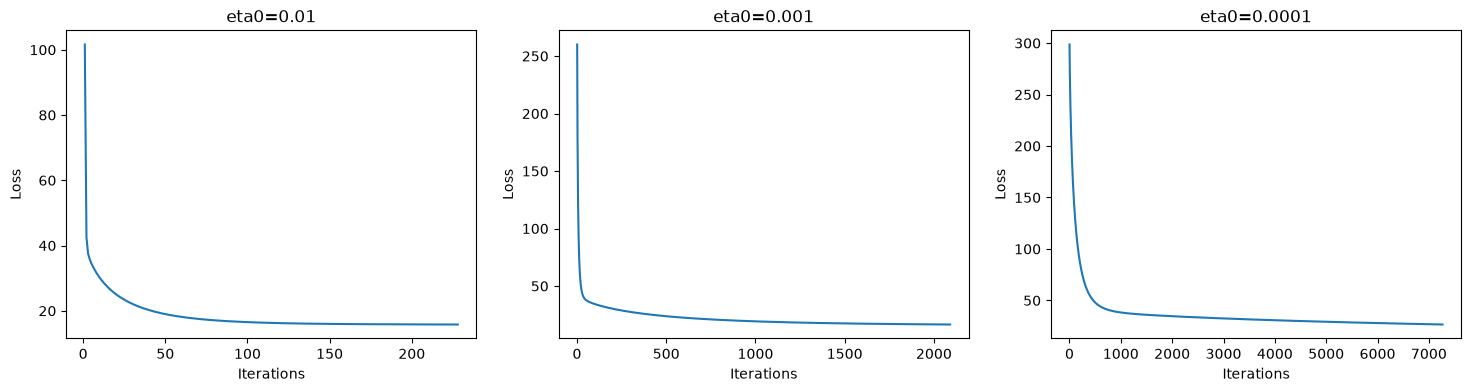

     eta0       MAE        MSE      RMSE        R2
0  0.0100  3.857478  30.864167  5.555553  0.579128
1  0.0010  3.846564  30.990084  5.566874  0.577411
2  0.0001  4.758721  47.198605  6.870124  0.356387
Best: 0.01


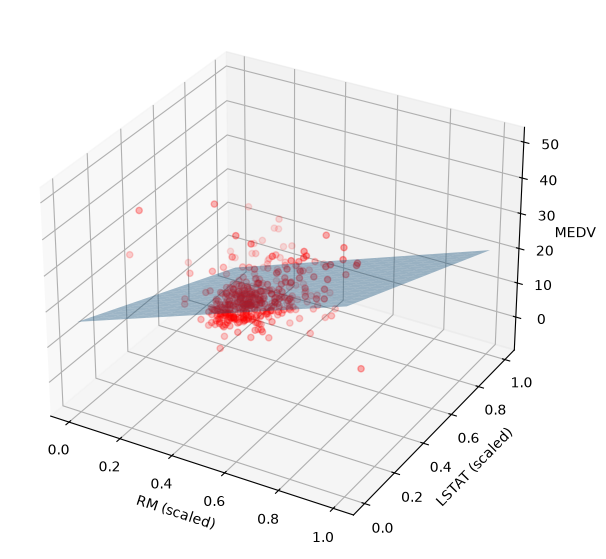

Predicted MEDV: 13.45722184717156


In [18]:
import io, re, contextlib
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1 + 2. Train and capture the loss per epoch (verbose=1 prints "Avg. loss")
def train(eta0):
    sgdr = SGDRegressor(learning_rate='invscaling', eta0=eta0, max_iter=10000, verbose=1)
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        sgdr.fit(X_train_s, y_train)
    losses = [float(v) for v in re.findall(r"Avg\. loss: ([\d\.eE+-]+)", buf.getvalue())]
    return sgdr, losses

# 3. Vary the learning rate
models, histories = {}, {}
for lr in [0.01, 0.001, 0.0001]:
    models[lr], histories[lr] = train(lr)
    print(lr, "stopped after", models[lr].n_iter_, "iterations")

fig, axs = plt.subplots(1, 3, figsize=(18,4))
for ax, lr in zip(axs, models):
    ax.plot(range(1, len(histories[lr])+1), histories[lr])
    ax.set_title(f"eta0={lr}"); ax.set_xlabel("Iterations"); ax.set_ylabel("Loss")
plt.show()

# 5. Metrics on the test set
rows = []
for lr, m in models.items():
    p = m.predict(X_test_s)
    mse = mean_squared_error(y_test, p)
    rows.append([lr, mean_absolute_error(y_test, p), mse, np.sqrt(mse), r2_score(y_test, p)])
res = pd.DataFrame(rows, columns=["eta0","MAE","MSE","RMSE","R2"]); print(res)
best_lr = res.loc[res["R2"].idxmax(), "eta0"]; best = models[best_lr]
print("Best:", best_lr)

# 6. Plane of the best model + scaled training data
a = np.linspace(0,1,20)
g1, g2 = np.meshgrid(a, a)
Z = best.intercept_[0] + best.coef_[0]*g1 + best.coef_[1]*g2
fig = plt.figure(figsize=(9,7)); ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_train_s[:,0], X_train_s[:,1], y_train, c='r', alpha=.6)
ax.plot_surface(g1, g2, Z, alpha=.4)
ax.set_xlabel(selected[0]+" (scaled)"); ax.set_ylabel(selected[1]+" (scaled)"); ax.set_zlabel("MEDV")
plt.show()

# 7. Prediction (replace with the values from the figure)
sample = pd.DataFrame([[5.713, 22.6]], columns=selected)   # order: RM, LSTAT
sample_s = scaler.transform(sample)
pred = best.predict(sample_s)
print("Predicted MEDV:", pred[0])

![title](sample.png)